In [ ]:
!python -m pip install pyyaml==5.1 # pyymal configuration for python detectron
import os ## File and directory
import sys # Python Runtime Envirnoment
import distutils.core # used to build and install python modules from setup.py

!git clone https://github.com/facebookresearch/detectron2.git ## clone into current directory

dist = distutils.core.run_setup("./detectron2/setup.py") # programmtically runs the setup.py script inside the cloned folder

!python -m pip install {' '.join([f"'{x}'"for x in dist.install_requires])}

sys.path.insert(0, os.path.abspath('./detectron2'))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.2/274.2 kB 10.7 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
Cloning into 'detectron2'...
remote: Enumerating objects: 16073, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 16073 (delta 35), reused 14 (delta 13), pack-reused 16020 (from 3)
Receiving objects: 100% (16073/16073), 6.84 MiB | 21.62 MiB/s, done.
Resolving deltas: 100% (11388/11388), done.
Ignoring dataclasses: markers 'python_version < "3.7"' don't match your en

In [ ]:
import torch

import detectron2


In [ ]:
torch.__version__

'2.11.0+cu130'

In [ ]:
detectron2.__version__

'0.6'

In [ ]:
import detectron2
from detectron2.utils.logger import setup_logger ##  logging system of detectron2
setup_logger() ## #initialisation of logger

<Logger detectron2 (DEBUG)>

In [ ]:
## Some Common Libarary are

import numpy as np
import os,cv2,json,random
from google.colab.patches import cv2_imshow

In [ ]:
#detectron 2 utilities
from detectron2 import model_zoo #pretrained model
from detectron2.engine import DefaultPredictor #wrapper around detectron 2 inference pipeline
from detectron2.config import get_cfg #path to weight, model configuration, architecture
from detectron2.utils.visualizer import Visualizer #to visualise, boxes
from detectron2.data import MetadataCatalog, DatasetCatalog

#metadatacatalog>> stores metadata for dataset (classname, keypoints)
#datasetcatalog >> register andretrieve the dataset for detectron 2

/content/detectron2/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [ ]:
import requests
import os

def download_image(url, filename):
  headers = {
      'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.36'
  }
  response = requests.get(url, stream=True, headers=headers)
  response.raise_for_status()

  with open(filename, "wb") as outfile:
    for image in response.iter_content(chunk_size=8192):
      outfile.write(image)
  print(f"The Image successfully downloaded: {filename}")

# Corrected the function call here (replaced '=' with calling the function)
download_image("https://images.pexels.com/photos/13872248/pexels-photo-13872248.jpeg", "pexels-photo-13872248.jpg")

The Image successfully downloaded: pexels-photo-13872248.jpg


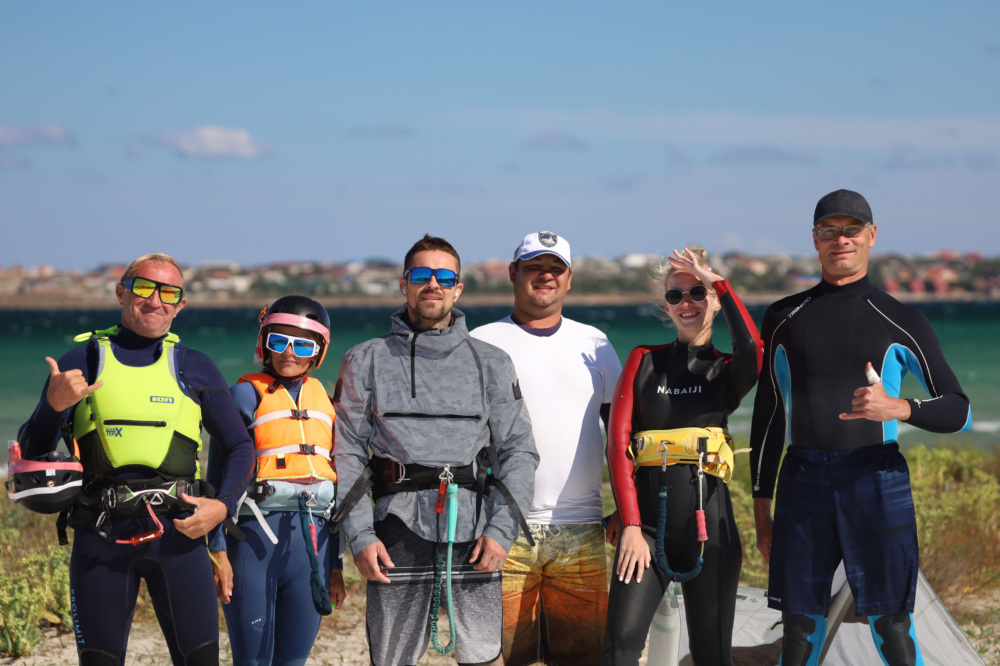

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

image_path = "/content/pexels-photo-13872248.jpg"
image = cv2.imread(image_path)

# Check if the image was successfully loaded before displaying
if image is not None:
    cv2_imshow(image)
else:
    print(f"Error: Could not load image from {image_path}. Please make sure the previous download step ran successfully.")

In [ ]:
cfg = get_cfg() # #it initializes a fresh detectron2 configuration object, it holds all model weights and config
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml"))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml")
cfg.MODEL.DEVICE = "cpu"
predictor = DefaultPredictor(cfg)
outputs = predictor(image)

[10/21 15:36:25 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-Detection/faster_rcnn_R_101_FPN_3x/137851257/model_final_f6e8b1.pkl ...


model_final_f6e8b1.pkl: 243MB [00:01, 227MB/s]                           
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1021 15:36:33.126000 392 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


In [ ]:
print(outputs)

{'instances': Instances(num_instances=6, image_height=4160, image_width=6240, fields=[pred_boxes: Boxes(tensor([[ 112.0213, 1584.7682, 1576.0919, 4152.6953],
        [2018.0801, 1476.3453, 3358.6194, 4154.3999],
        [4668.7036, 1193.1257, 6040.2627, 4127.9497],
        [3806.4775, 1550.2720, 4728.1191, 4154.7476],
        [2929.6687, 1427.1233, 3913.2791, 4100.4180],
        [1357.4598, 1823.7299, 2139.9771, 4111.7246]])), scores: tensor([0.9996, 0.9996, 0.9991, 0.9985, 0.9979, 0.9965]), pred_classes: tensor([0, 0, 0, 0, 0, 0])])}


In [ ]:
print(outputs["instances"].pred_boxes)

Boxes(tensor([[ 112.0213, 1584.7682, 1576.0919, 4152.6953],
        [2018.0801, 1476.3453, 3358.6194, 4154.3999],
        [4668.7036, 1193.1257, 6040.2627, 4127.9497],
        [3806.4775, 1550.2720, 4728.1191, 4154.7476],
        [2929.6687, 1427.1233, 3913.2791, 4100.4180],
        [1357.4598, 1823.7299, 2139.9771, 4111.7246]]))


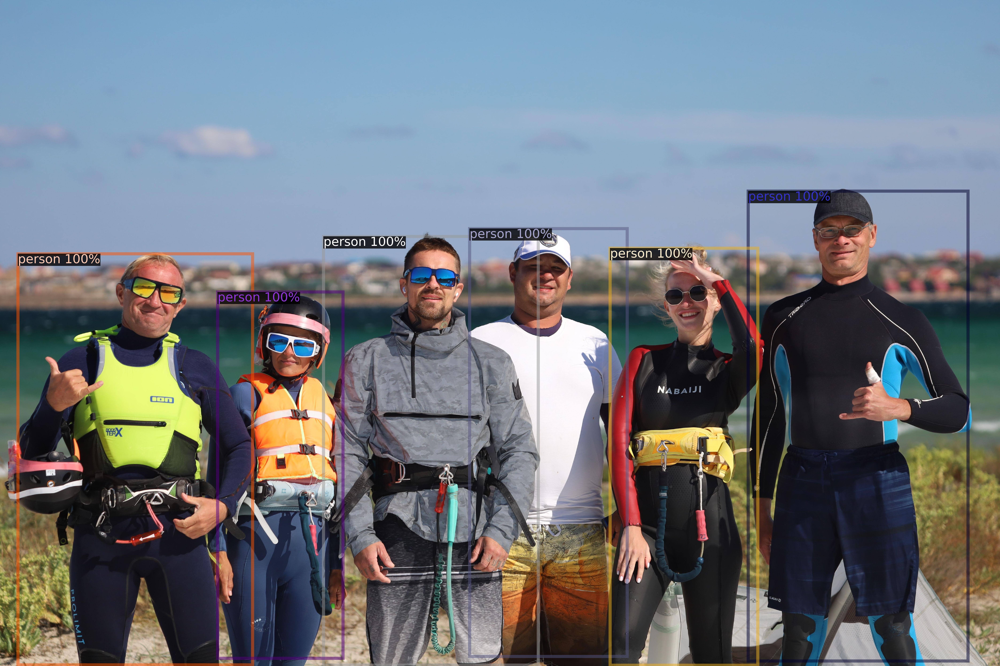

In [ ]:
# visualization

v = Visualizer(image[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)
out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
cv2_imshow(out.get_image()[:, :, ::-1])